# Praktikum 8 — Neural Network
**Mata Kuliah:** Praktikum Penambangan Data  
**Nama:** Hafidz Rizqullah Prasetya  
**NIM:** 24/535493/SV/24243  
**Kelas:** PL5A1  
**Dosen Pengampu:** Dr. Imam Fahrurrozi, S.T., M.Cs.  
**Program Studi:** D-IV Teknologi Rekayasa Perangkat Lunak  
**Departemen:** Teknik Elektro dan Informatika, Sekolah Vokasi, Universitas Gadjah Mada  

---
Notebook ini memuat seluruh implementasi praktikum Pertemuan 8, meliputi:
1. **Percobaan Latihan Klasifikasi:** Prediksi *Bank Customer Churn* menggunakan `MLPClassifier`.
2. **Percobaan Latihan Regresi:** Prediksi harga rumah pada *King County House Sales* menggunakan `MLPRegressor`.
3. **Tugas 1:** Pemahaman dan analisis karakteristik dataset *Bank Customer Churn* dan *KC House Data*.
4. **Tugas 2 (Mandiri):** Eksperimen pemodelan klasifikasi mandiri (*Breast Cancer Wisconsin Diagnostic*) dan regresi mandiri (*California Housing*) dengan eksplorasi multi-arsitektur dan evaluasi komprehensif.


## 1. Persiapan Lingkungan dan Impor Pustaka
Mengimpor seluruh pustaka yang diperlukan untuk manipulasi array dan dataframe (`numpy`, `pandas`), visualisasi (`matplotlib`, `seaborn`), pra-pemrosesan (`StandardScaler`, `LabelEncoder`, `SimpleImputer`), pemodelan neural network (`MLPClassifier`, `MLPRegressor`), serta metrik evaluasi klasifikasi dan regresi.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_squared_error, mean_absolute_error, r2_score, roc_auc_score
)
from sklearn.datasets import load_breast_cancer, fetch_california_housing

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

print("Pustaka berhasil diimpor dan lingkungan siap.")

Pustaka berhasil diimpor dan lingkungan siap.


## 2. Percobaan Latihan Klasifikasi: Bank Customer Churn
Percobaan pertama menerapkan arsitektur *Multilayer Perceptron* (MLP) untuk klasifikasi biner pada dataset *Bank Customer Churn*. Tujuannya adalah memprediksi apakah seorang nasabah bank akan mempertahankan layanannya (*Existing Customer*) atau menutup rekeningnya (*Attrited Customer*).

### 2.1 Membaca Dataset Bank Churners
Dataset dimuat langsung dari repositori publik GitHub agar proses praktikum sepenuhnya dapat direproduksi (*reproducible*).


In [2]:
URL_CHURN = "https://raw.githubusercontent.com/ganjar87/data_science_practice/main/BankChurners.csv"
df = pd.read_csv(URL_CHURN)

print("Dimensi dataset Bank Customer Churn:", df.shape)
print("Baris data dari atas (head):")
df.head()

Dimensi dataset Bank Customer Churn: (10127, 21)
Baris data dari atas (head):


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


### 2.2 Menampilkan Lima Baris Terakhir Dataset
Pemeriksaan lima baris terbawah (`tail`) memastikan integritas data hingga baris akhir dan memberikan gambaran variasi sampel.


In [3]:
print("Baris data dari bawah (tail):")
df.tail()

Baris data dari bawah (tail):


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000
10126,714337233,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,6,2,4,10388.0,1961,8427.0,0.703,10294,61,0.649,0.189


### 2.3 Pemeriksaan Struktur Kolom dan Tipe Data
Menggunakan metode `.info()` untuk mengetahui tipe data tiap atribut serta memastikan tidak ada anomali tipe data awal.


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  str    
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  str    
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           10127 non-null  str    
 6   Marital_Status            10127 non-null  str    
 7   Income_Category           10127 non-null  str    
 8   Card_Category             10127 non-null  str    
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  float64
 14  Total_Revolving_B

### 2.4 Eksplorasi Visual: Histogram Sebaran Fitur Numerik
Menampilkan histogram untuk atribut numerik utama guna memahami bentuk distribusi data nasabah.


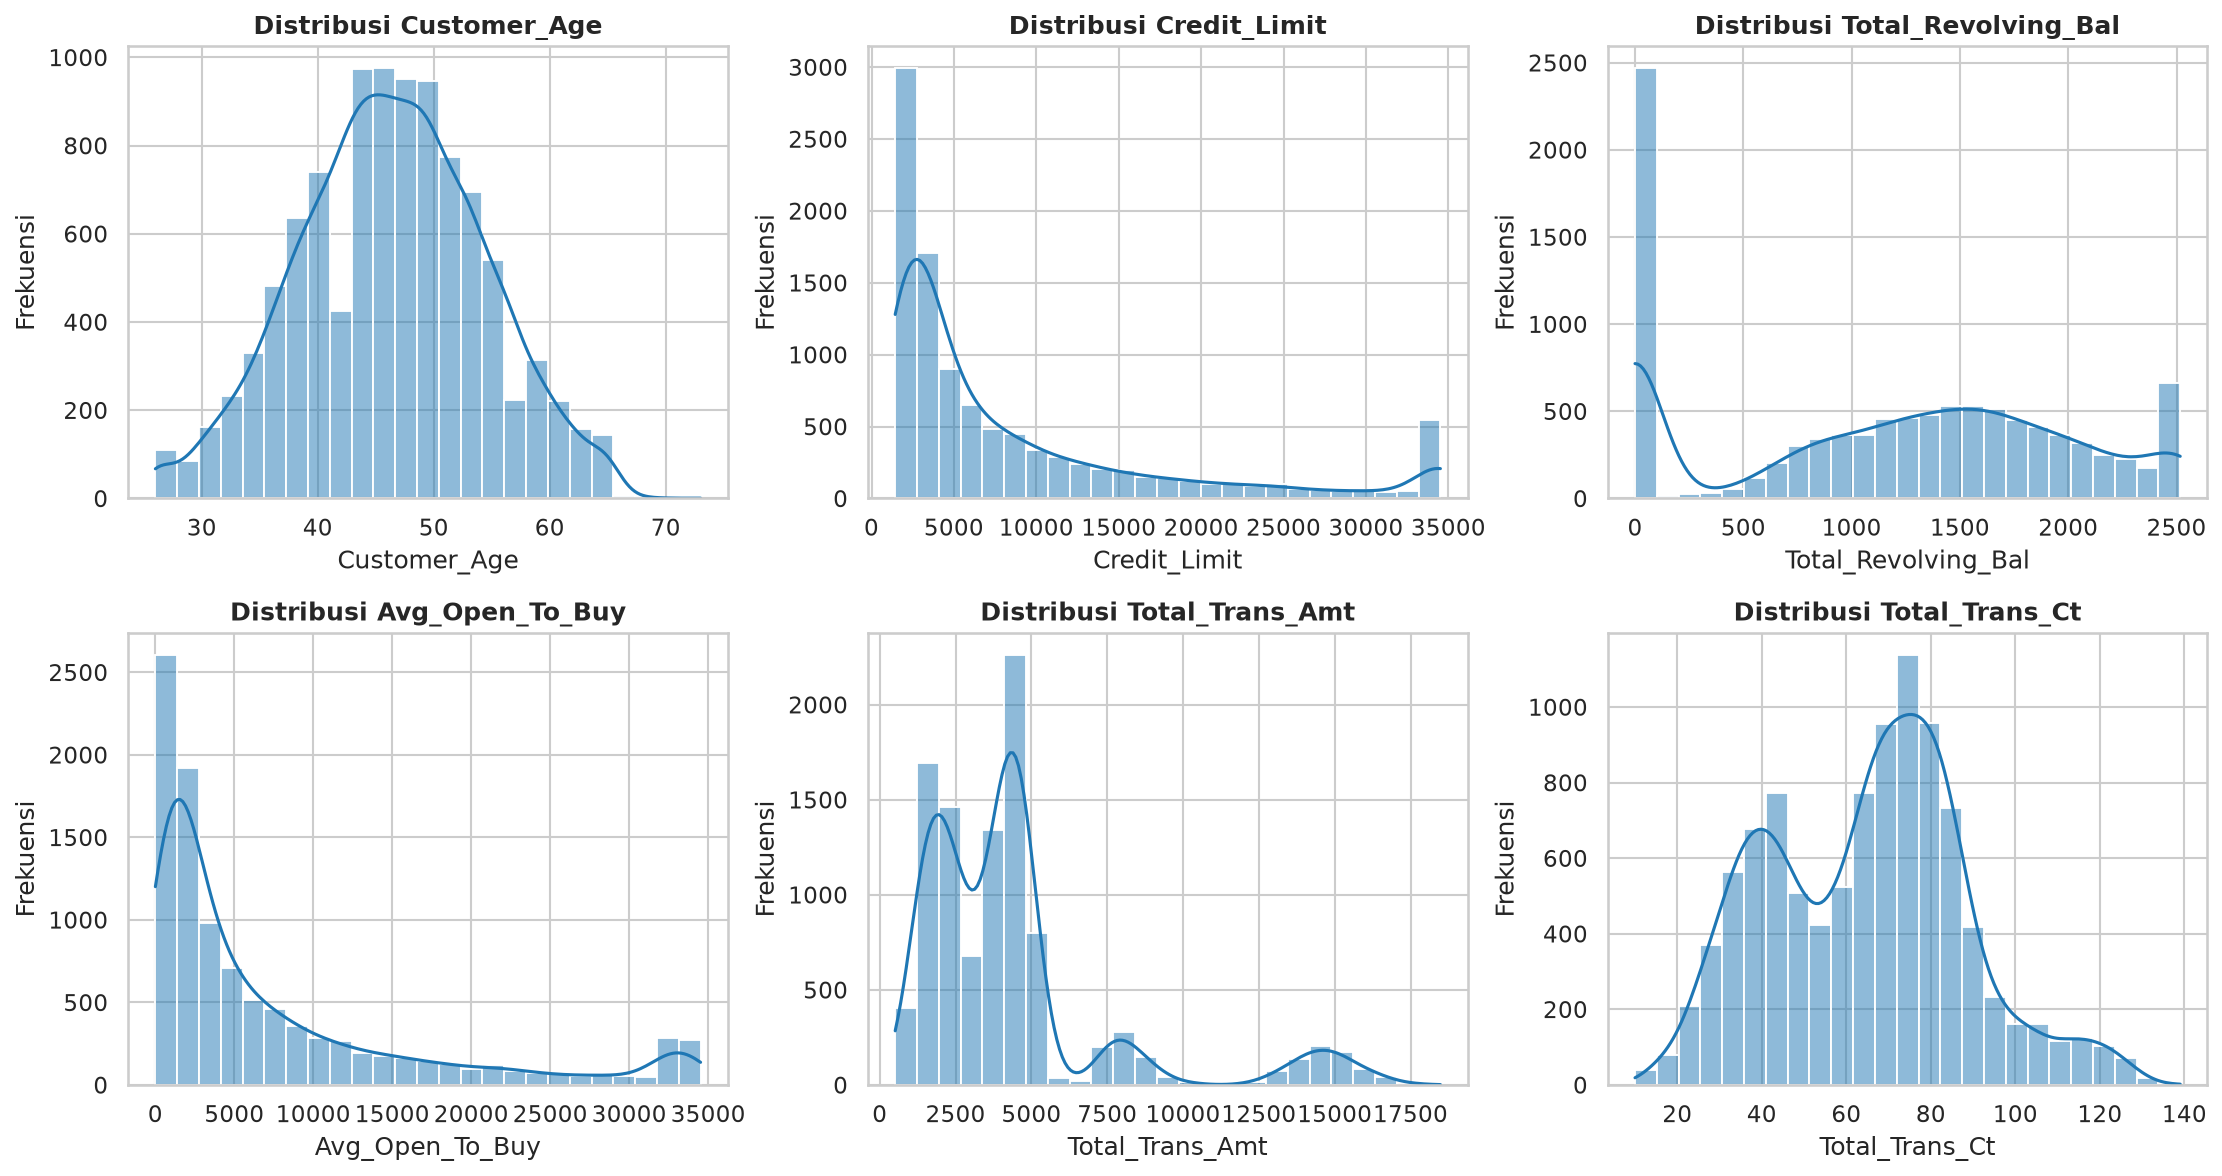

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fitur_plot = ['Customer_Age', 'Credit_Limit', 'Total_Revolving_Bal', 
              'Avg_Open_To_Buy', 'Total_Trans_Amt', 'Total_Trans_Ct']

for ax, col in zip(axes.flatten(), fitur_plot):
    sns.histplot(df[col], kde=True, ax=ax, color='#1f77b4', bins=25)
    ax.set_title(f'Distribusi {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### 2.5 Pemeriksaan Proporsi Kelas Target
Mengecek distribusi persentase nasabah aktif (*Existing Customer*) terhadap nasabah churn (*Attrited Customer*).


Jumlah per kelas target:
 - Existing Customer: 8500 nasabah (83.93%)
 - Attrited Customer: 1627 nasabah (16.07%)


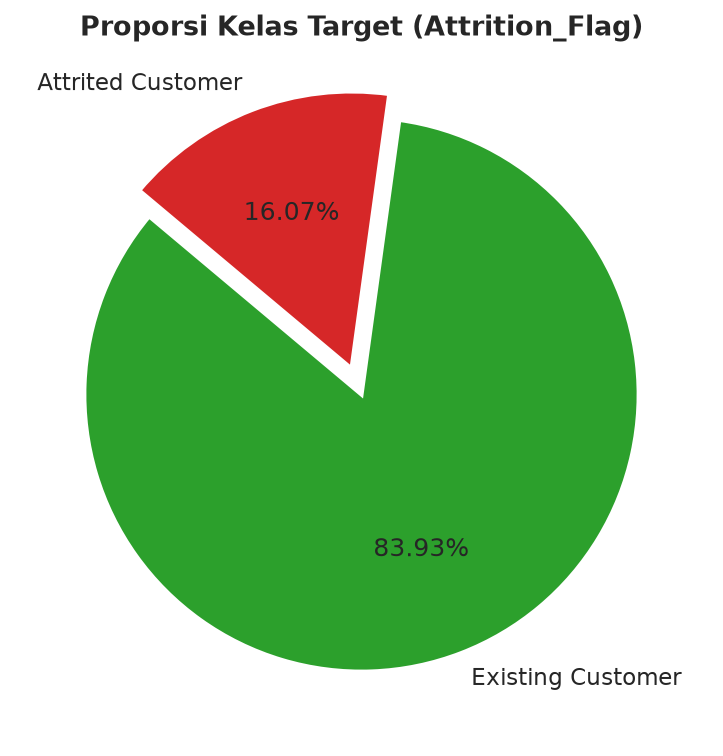

In [6]:
proporsi_target = df['Attrition_Flag'].value_counts()
persentase_target = df['Attrition_Flag'].value_counts(normalize=True) * 100

print("Jumlah per kelas target:")
for k, v in proporsi_target.items():
    print(f" - {k}: {v} nasabah ({persentase_target[k]:.2f}%)")

plt.figure(figsize=(6, 6))
plt.pie(proporsi_target, labels=proporsi_target.index, autopct='%.2f%%', 
        colors=['#2ca02c', '#d62728'], startangle=140, explode=[0, 0.1],
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
plt.title("Proporsi Kelas Target (Attrition_Flag)", fontsize=13, fontweight='bold')
plt.show()

### 2.6 Pemeriksaan Nilai Hilang (Missing Values)
Memastikan keberadaan nilai kosong (`null`) pada seluruh kolom dataset.


In [7]:
missing_val = df.isnull().sum()
print("Jumlah nilai kosong per kolom:")
print(missing_val)
print("\nTotal nilai kosong pada dataset:", missing_val.sum())

Jumlah nilai kosong per kolom:
CLIENTNUM                   0
Attrition_Flag              0
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
dtype: int64

Total nilai kosong pada dataset: 0


### 2.7 Identifikasi Atribut Kategorikal dan Numerik
Memisahkan fitur prediktor ($X$) dari kolom identitas nasabah (`CLIENTNUM`) dan kolom label target (`Attrition_Flag`), kemudian menginventarisasi kolom kategorikal bertipe objek.


In [8]:
df_X = df.drop(columns=['CLIENTNUM', 'Attrition_Flag'])
df_y = df['Attrition_Flag']

cats = df_X.select_dtypes(include=['object']).columns
print("Atribut kategorikal teridentifikasi:")
print(cats.tolist())
print(f"\nJumlah atribut kategorikal: {len(cats)} | Jumlah atribut total: {df_X.shape[1]}")

Atribut kategorikal teridentifikasi:
['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']

Jumlah atribut kategorikal: 5 | Jumlah atribut total: 19


### 2.8 Pra-Pemrosesan: Encoding Variabel Kategorikal dan Target
Mengubah label target string menjadi representasi numerik biner (0 dan 1) dengan `LabelEncoder`, serta mengonversi seluruh variabel kategorikal prediktor menjadi nilai numerik terurut.


In [9]:
df_X_enc = df_X.copy()

le_y = LabelEncoder()
y = le_y.fit_transform(df_y)
print("Mapping target Attrition_Flag:", dict(zip(le_y.classes_, le_y.transform(le_y.classes_))))

label_encoders = {}
for col in cats:
    le = LabelEncoder()
    df_X_enc[col] = le.fit_transform(df_X_enc[col])
    label_encoders[col] = le

print("Encoding seluruh fitur kategorikal selesai.")
print("Lima baris pertama prediktor numerik ter-encode:")
df_X_enc.head()

Mapping target Attrition_Flag: {'Attrited Customer': np.int64(0), 'Existing Customer': np.int64(1)}
Encoding seluruh fitur kategorikal selesai.
Lima baris pertama prediktor numerik ter-encode:


,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,45,1,3,3,1,2,0,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,49,0,5,2,2,4,0,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,51,1,3,2,1,3,0,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,40,0,4,3,3,4,0,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,40,1,3,5,1,2,0,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


### 2.9 Pemisahan Data Latih dan Uji serta Standarisasi Fitur
Menerapkan *hold-out validation* dengan rasio 70% data latih dan 30% data uji (`random_state=42`). Selanjutnya, fitur dinormalisasi menggunakan `StandardScaler` agar algoritma optimasi berbasis gradien (*Backpropagation*) konvergen secara stabil.


In [10]:
X = df_X_enc.astype(float).values
y = y.astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensi set pelatihan: {X_train_scaled.shape}")
print(f"Dimensi set pengujian : {X_test_scaled.shape}")
print("\nContoh nilai fitur sampel pertama (X_train[0]) setelah penskalaan:")
print(X_train_scaled[0])

Dimensi set pelatihan: (7088, 19)
Dimensi set pengujian : (3039, 19)

Contoh nilai fitur sampel pertama (X_train[0]) setelah penskalaan:
[ 0.33519339  1.05692234 -0.25437357  0.4990858  -0.61710507 -0.56580813
 -0.25591165  0.25586758 -0.51407227 -0.33752656 -2.22835505 -0.05917368
  0.98686487 -0.14826286 -0.57038549 -0.90317904 -1.65490765 -1.12681489
 -0.11093226]


### 2.10 Pelatihan Model MLPClassifier
Melatih model jaringan syaraf tiruan menggunakan parameter `max_iter=500` sesuai langkah pada Modul Pertemuan 8.


In [11]:
model = MLPClassifier(max_iter=500, random_state=42)
model.fit(X_train_scaled, y_train)

print("Status pelatihan model:")
print(model)
print(f"Jumlah iterasi hingga selesai: {model.n_iter_}")
print(f"Fungsi rugi akhir (loss): {model.loss_:.6f}")

Status pelatihan model:
MLPClassifier(max_iter=500, random_state=42)
Jumlah iterasi hingga selesai: 500
Fungsi rugi akhir (loss): 0.018224


### 2.11 Pemeriksaan Koefisien Bobot Jaringan (coefs_)
Memeriksa matriks bobot sinapsis antar-lapisan neuron (`model.coefs_`).


In [12]:
print("Jumlah lapisan koneksi bobot:", len(model.coefs_))
print(f"Dimensi bobot Input -> Hidden Layer: {model.coefs_[0].shape}")
print(f"Dimensi bobot Hidden -> Output Layer: {model.coefs_[1].shape}")
print("\nSebagian bobot neuron pertama lapisan tersembunyi:")
print(model.coefs_[0][:5, :3])

Jumlah lapisan koneksi bobot: 2
Dimensi bobot Input -> Hidden Layer: (19, 100)
Dimensi bobot Hidden -> Output Layer: (100, 1)

Sebagian bobot neuron pertama lapisan tersembunyi:
[[-0.3857342   0.10840396  0.79216726]
 [-0.86985632  0.02028376  0.07048071]
 [-0.15697107 -0.33563439 -0.27627508]
 [-0.10189953  0.08670851 -0.22915727]
 [-0.00866776  0.32470209  0.04354969]]


### 2.12 Evaluasi Performa Model Klasifikasi
Menghitung metrik Akurasi, Presisi, Recall, F1-Score, dan menampilkan matriks kontingensi (*Confusion Matrix*).


Akurasi   : 0.9381 (93.81%)
Presisi   : 0.9605
Recall    : 0.9658
F1-Score  : 0.9631

Confusion Matrix:
 [[ 395  101]
 [  87 2456]]


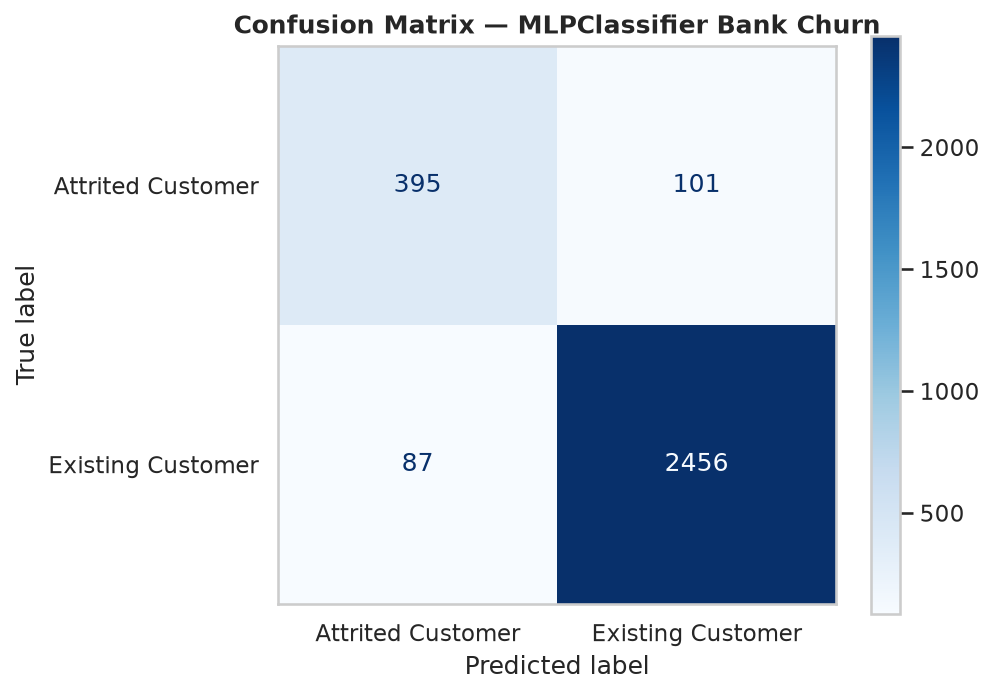

In [13]:
y_pred = model.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Akurasi   : {acc:.4f} ({acc*100:.2f}%)")
print(f"Presisi   : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("\nConfusion Matrix:\n", cm)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_y.classes_)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Confusion Matrix — MLPClassifier Bank Churn", fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()

### 2.13 Pengujian Prediksi pada Profil Nasabah Baru
Menguji kemampuan inferensi model terhadap 2 contoh data profil nasabah baru sesuai skenario praktikum.


In [14]:
data_uji_baru = [
    {
        'Customer_Age': 60, 'Gender': 'F', 'Dependent_count': 5, 'Education_Level': 'Graduate',
        'Marital_Status': 'Single', 'Income_Category': 'Less than $40K', 'Card_Category': 'Blue',
        'Months_on_book': 44, 'Total_Relationship_Count': 6, 'Months_Inactive_12_mon': 1,
        'Contacts_Count_12_mon': 2, 'Credit_Limit': 8720, 'Total_Revolving_Bal': 80,
        'Avg_Open_To_Buy': 7382, 'Total_Amt_Chng_Q4_Q1': 0.637, 'Total_Trans_Amt': 1329,
        'Total_Trans_Ct': 40, 'Total_Ct_Chng_Q4_Q1': 0.732, 'Avg_Utilization_Ratio': 0.010
    },
    {
        'Customer_Age': 40, 'Gender': 'M', 'Dependent_count': 2, 'Education_Level': 'Graduate',
        'Marital_Status': 'Married', 'Income_Category': '$60K - $80K', 'Card_Category': 'Blue',
        'Months_on_book': 36, 'Total_Relationship_Count': 4, 'Months_Inactive_12_mon': 2,
        'Contacts_Count_12_mon': 3, 'Credit_Limit': 4500, 'Total_Revolving_Bal': 1200,
        'Avg_Open_To_Buy': 3300, 'Total_Amt_Chng_Q4_Q1': 0.720, 'Total_Trans_Amt': 4200,
        'Total_Trans_Ct': 75, 'Total_Ct_Chng_Q4_Q1': 0.810, 'Avg_Utilization_Ratio': 0.267
    }
]

df_input = pd.DataFrame(data_uji_baru)
original_cols = df_X_enc.columns
df_input = df_input.reindex(columns=original_cols, fill_value=0)

for col in cats:
    df_input[col] = label_encoders[col].transform(df_input[col].astype(str))

X_input_scaled = scaler.transform(df_input.astype(float).values)
prediksi_baru = model.predict(X_input_scaled)

print("Hasil Inferensi Data Nasabah Baru:")
for idx, pred in enumerate(prediksi_baru):
    label = le_y.inverse_transform([int(pred)])[0]
    print(f" Nasabah {idx+1}: Prediksi Kelas = {pred} ({label})")

Hasil Inferensi Data Nasabah Baru:
 Nasabah 1: Prediksi Kelas = 1.0 (Existing Customer)
 Nasabah 2: Prediksi Kelas = 1.0 (Existing Customer)


### 2.14 Eksplorasi Optimasi Model Klasifikasi Churn
Menguji konfigurasi arsitektur multi-layer `(64, 32)` dengan regularisasi $L_2$ (`alpha=0.01`) dan `early_stopping=True` untuk mencegah overfitting serta mempercepat waktu konvergensi jaringan.


In [15]:
model_opt = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.01, early_stopping=True, max_iter=500, random_state=42)
model_opt.fit(X_train_scaled, y_train)
y_pred_opt = model_opt.predict(X_test_scaled)

print("--- Performa MLPClassifier Optimal dengan Early Stopping ---")
print(f"Akurasi : {accuracy_score(y_test, y_pred_opt):.4f}")
print(f"Presisi : {precision_score(y_test, y_pred_opt):.4f}")
print(f"Recall  : {recall_score(y_test, y_pred_opt):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_opt):.4f}")
print(f"Konvergensi tercapai pada iterasi: {model_opt.n_iter_}")
print("\nLaporan Klasifikasi Lengkap:\n", classification_report(y_test, y_pred_opt, target_names=le_y.classes_))

--- Performa MLPClassifier Optimal dengan Early Stopping ---
Akurasi : 0.9329
Presisi : 0.9581
Recall  : 0.9619
F1-Score: 0.9600
Konvergensi tercapai pada iterasi: 74

Laporan Klasifikasi Lengkap:
                    precision    recall  f1-score   support

Attrited Customer       0.80      0.78      0.79       496
Existing Customer       0.96      0.96      0.96      2543

         accuracy                           0.93      3039
        macro avg       0.88      0.87      0.88      3039
     weighted avg       0.93      0.93      0.93      3039



## 3. Percobaan Latihan Regresi: King County House Sales
Percobaan kedua menerapkan `MLPRegressor` untuk memprediksi harga penjualan rumah bernilai kontinu pada dataset *King County House Sales* (`kc_house_data.csv`).

### 3.1 Membaca Dataset KC House Data
Dataset diunduh dari repositori publik dan ditampilkan lima baris teratasnya.


In [16]:
URL_KC = "https://raw.githubusercontent.com/ganjar87/data_science_practice/main/kc_house_data.csv"
df_kc = pd.read_csv(URL_KC)

print("Dimensi dataset KC House Sales:", df_kc.shape)
print("Lima baris teratas:")
df_kc.head()

Dimensi dataset KC House Sales: (21613, 21)
Lima baris teratas:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### 3.2 Pemeriksaan Missing Values pada Dataset KC House
Memeriksa keberadaan nilai hilang pada seluruh kolom dataset regresi.


In [17]:
missing_kc = df_kc.isnull().sum()
print("Jumlah missing values per kolom KC House Data:")
print(missing_kc[missing_kc > 0] if (missing_kc > 0).any() else "Tidak ditemukan missing values pada seluruh kolom.")
print("\nTotal missing values:", missing_kc.sum())

Jumlah missing values per kolom KC House Data:
Tidak ditemukan missing values pada seluruh kolom.

Total missing values: 0


### 3.3 Visualisasi Histogram Sebaran Fitur Numerik
Menganalisis sebaran variabel fitur numerik seperti `price`, `bedrooms`, `bathrooms`, `sqft_living`, `grade`, dll.


<Figure size 2400x1800 with 0 Axes>

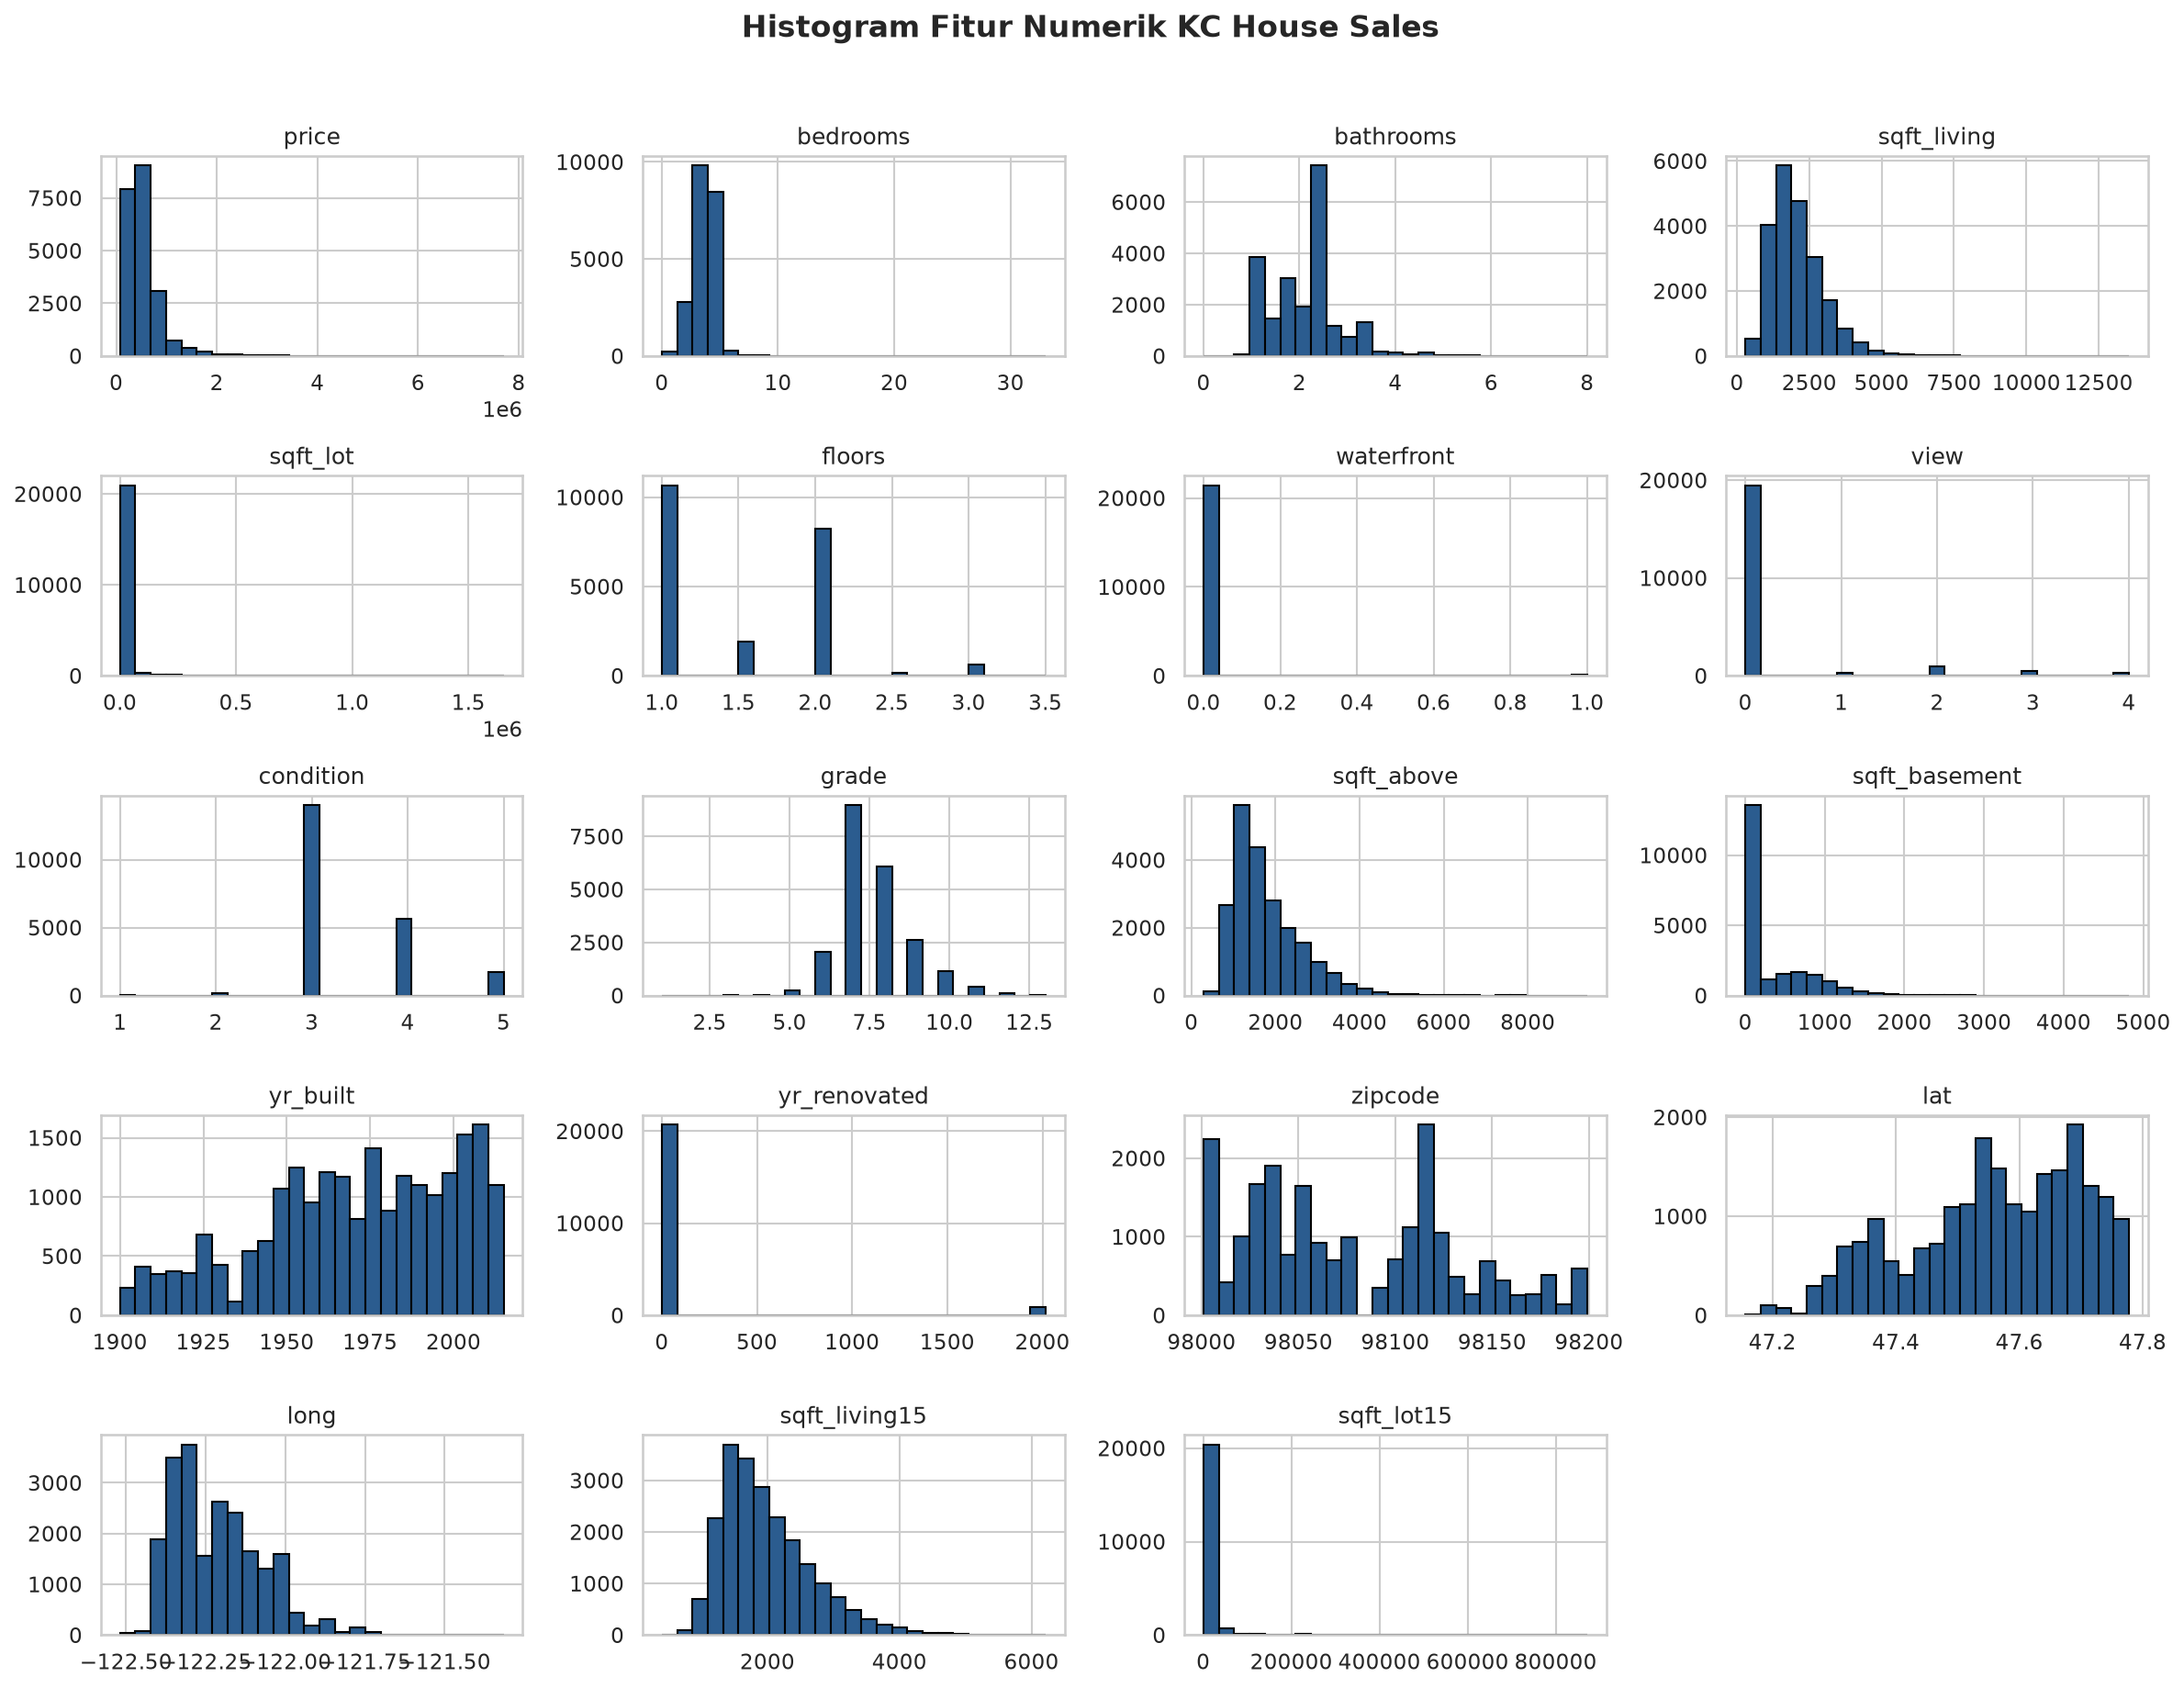

In [18]:
plt.figure(figsize=(16, 12))
df_kc.drop(columns=['id', 'date']).hist(figsize=(16, 12), bins=25, color='#2b5c8f', edgecolor='black', grid=True)
plt.suptitle("Histogram Fitur Numerik KC House Sales", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.4 Identifikasi Tipe Fitur dan Pembersihan Kolom Non-Fitur
Membuang kolom `id`, `date`, dan target `price` dari matriks fitur, lalu memeriksa ada tidaknya kolom bertipe kategorikal.


In [19]:
df_kc_X = df_kc.drop(columns=['id', 'date', 'price'])
df_kc_y = df_kc['price']

cats_kc = df_kc_X.select_dtypes(include=['object']).columns
print("Atribut kategorikal pada prediktor KC House:")
print(cats_kc.tolist() if len(cats_kc) > 0 else "Tidak ada atribut bertipe objek/kategorikal (seluruh prediktor numerik).")
print(f"Jumlah prediktor numerik: {df_kc_X.shape[1]}")

Atribut kategorikal pada prediktor KC House:
Tidak ada atribut bertipe objek/kategorikal (seluruh prediktor numerik).
Jumlah prediktor numerik: 18


### 3.5 Pemisahan Data Latih-Uji dan Imputasi
Menggunakan `SimpleImputer` dengan strategi *mean* dan membagi dataset menjadi 70% data latih dan 30% data uji (`random_state=42`) sesuai instruksi modul.


In [20]:
imputer = SimpleImputer(strategy='mean')
X_kc = imputer.fit_transform(df_kc_X)
y_kc = df_kc_y.astype(float).values

X_kc_train, X_kc_test, y_kc_train, y_kc_test = train_test_split(X_kc, y_kc, test_size=0.3, random_state=42)

print(f"Dimensi data latih regresi: {X_kc_train.shape}")
print(f"Dimensi data uji regresi  : {X_kc_test.shape}")

Dimensi data latih regresi: (15129, 18)
Dimensi data uji regresi  : (6484, 18)


### 3.6 Pelatihan Model MLPRegressor (Langkah Sesuai Modul)
Melatih model `MLPRegressor()` default sesuai panduan modul tanpa penskalaan awal, dan mengamati koefisien determinasi ($R^2$) serta prediksi 10 sampel pertama.


In [21]:
reg = MLPRegressor(random_state=42)
reg.fit(X_kc_train, y_kc_train)

r2_train = reg.score(X_kc_train, y_kc_train)
r2_test = reg.score(X_kc_test, y_kc_test)
y_kc_pred = reg.predict(X_kc_test)

print(f"Coef of determination training (R2): {r2_train:.6f}")
print(f"Coef of determination testing  (R2): {r2_test:.6f}")
print("\nSepuluh nilai prediksi pertama:")
print(np.round(y_kc_pred[:10], 2))
print("\nSepuluh nilai aktual pertama:")
print(y_kc_test[:10])

Coef of determination training (R2): 0.556412
Coef of determination testing  (R2): 0.541798

Sepuluh nilai prediksi pertama:
[ 493248.99  742274.66 1086597.35 1330747.86  651274.98  387426.3
  659738.4   523827.82  482617.58  347880.86]

Sepuluh nilai aktual pertama:
[ 365000.  865000. 1038000. 1490000.  711000.  211000.  790000.  680000.
  384500.  605000.]


### 3.7 Evaluasi Performa Model Regresi
Menghitung nilai galat absolut dan kuadrat: *Root Mean Squared Error* (RMSE) serta skor $R^2$ pengujian.


In [22]:
mse_kc = mean_squared_error(y_kc_test, y_kc_pred)
rmse_kc = np.sqrt(mse_kc)
mae_kc = mean_absolute_error(y_kc_test, y_kc_pred)
r2_kc = r2_score(y_kc_test, y_kc_pred)

print(f"Mean Absolute Error (MAE) : ${mae_kc:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_kc:,.2f}")
print(f"Coefficient of Determination (R2): {r2_kc:.6f}")

Mean Absolute Error (MAE) : $164,994.64
Root Mean Squared Error (RMSE): $257,194.63
Coefficient of Determination (R2): 0.541798


### 3.8 Visualisasi Perbandingan Nilai Aktual vs Prediksi
Membuat diagram batang komparasi antara nilai riil (*actual*) dan nilai taksiran (*predicted*) untuk 30 sampel data uji pertama.


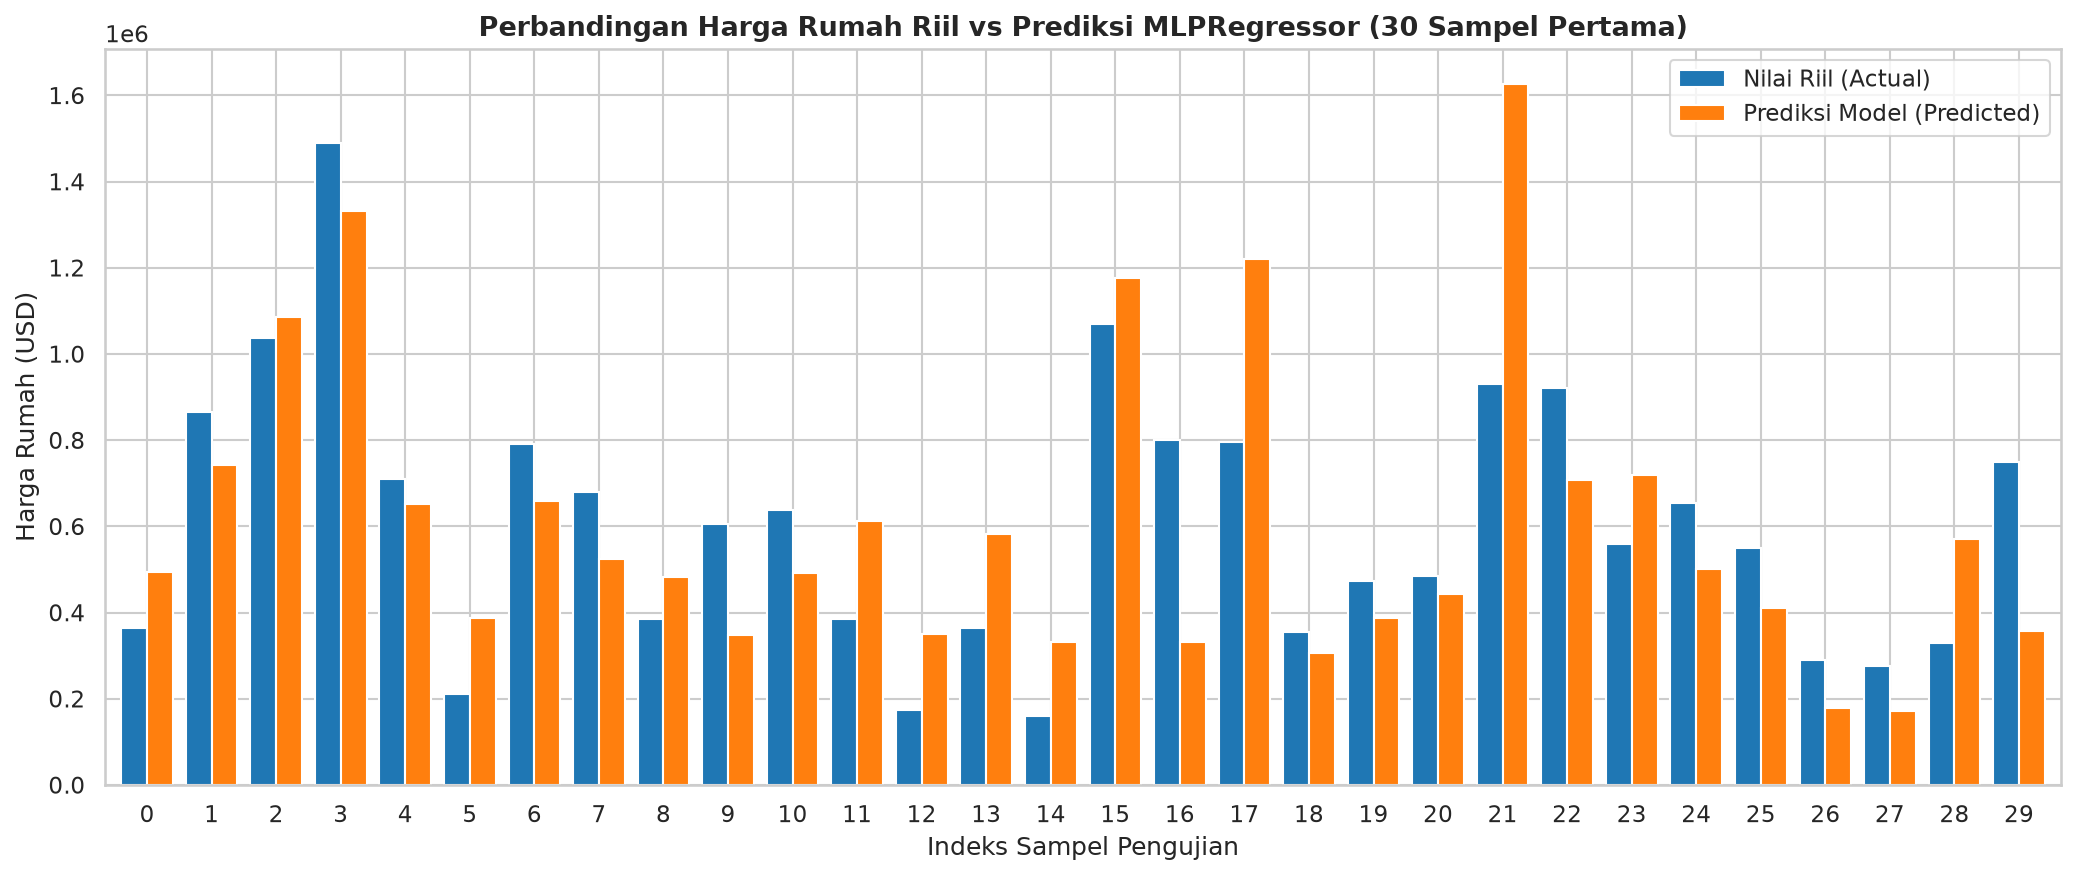

In [23]:
data1 = pd.DataFrame(y_kc_test[:30], columns=['real'])
data2 = pd.DataFrame(y_kc_pred[:30], columns=['predicted'])
df_bar = pd.concat([data1, data2], axis=1)

fig, ax = plt.subplots(figsize=(14, 6))
df_bar.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'], width=0.8)
plt.title("Perbandingan Harga Rumah Riil vs Prediksi MLPRegressor (30 Sampel Pertama)", fontsize=13, fontweight='bold')
plt.xlabel("Indeks Sampel Pengujian")
plt.ylabel("Harga Rumah (USD)")
plt.legend(["Nilai Riil (Actual)", "Prediksi Model (Predicted)"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.9 Peningkatan Performa: Dampak Standarisasi Fitur pada MLPRegressor
Neural Network sangat sensitif terhadap rentang skala fitur numerik. Fitur luas tanah (`sqft_lot`) bernilai puluhan ribu, sedangkan jumlah kamar tidur (`bedrooms`) bernilai satuan. Dengan menerapkan `StandardScaler` sebelum pelatihan, proses *gradient descent* berjalan jauh lebih efektif.


In [24]:
scaler_kc = StandardScaler().fit(X_kc_train)
X_kc_tr_sc = scaler_kc.transform(X_kc_train)
X_kc_te_sc = scaler_kc.transform(X_kc_test)

reg_scaled = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42, early_stopping=True)
reg_scaled.fit(X_kc_tr_sc, y_kc_train)

y_pred_sc = reg_scaled.predict(X_kc_te_sc)
rmse_sc = np.sqrt(mean_squared_error(y_kc_test, y_pred_sc))
r2_sc = r2_score(y_kc_test, y_pred_sc)

print("--- Performa MLPRegressor Setelah Standarisasi Fitur ---")
print(f"R2 Score Awal (Tanpa Scaling)     : {r2_kc:.4f}  | RMSE: ${rmse_kc:,.2f}")
print(f"R2 Score Baru (Dengan Scaling MLP): {r2_sc:.4f}  | RMSE: ${rmse_sc:,.2f}")
print(f"Peningkatan R2: +{((r2_sc - r2_kc) / abs(r2_kc))*100:.2f}% | Penurunan RMSE: -${(rmse_kc - rmse_sc):,.2f}")

--- Performa MLPRegressor Setelah Standarisasi Fitur ---
R2 Score Awal (Tanpa Scaling)     : 0.5418  | RMSE: $257,194.63
R2 Score Baru (Dengan Scaling MLP): 0.7647  | RMSE: $184,300.72
Peningkatan R2: +41.14% | Penurunan RMSE: -$72,893.91


## 4. Tugas dan Analisis
### 4.1 Tugas 1: Pemahaman dan Karakteristik Dataset
Tugas 1 mewajibkan penguraian latar belakang, tujuan bisnis, dan karakteristik seluruh fitur yang tersedia pada kedua dataset praktikum: *Bank Customer Churn* dan *KC House Data*.


In [25]:
churn_summary = pd.DataFrame({
    'Tipe Data': df.dtypes,
    'Jumlah Nilai Unik': df.nunique(),
    'Jumlah Missing': df.isnull().sum(),
    'Contoh Nilai': [df[col].iloc[0] for col in df.columns]
})
print("Ringkasan Fitur Bank Customer Churn Dataset:")
print(churn_summary)

Ringkasan Fitur Bank Customer Churn Dataset:
                         Tipe Data  Jumlah Nilai Unik  Jumlah Missing       Contoh Nilai
CLIENTNUM                    int64              10127               0          768805383
Attrition_Flag                 str                  2               0  Existing Customer
Customer_Age                 int64                 45               0                 45
Gender                         str                  2               0                  M
Dependent_count              int64                  6               0                  3
Education_Level                str                  7               0        High School
Marital_Status                 str                  4               0            Married
Income_Category                str                  6               0        $60K - $80K
Card_Category                  str                  4               0               Blue
Months_on_book               int64                 44            

In [26]:
kc_summary = pd.DataFrame({
    'Tipe Data': df_kc.dtypes,
    'Jumlah Nilai Unik': df_kc.nunique(),
    'Jumlah Missing': df_kc.isnull().sum(),
    'Contoh Nilai': [df_kc[col].iloc[0] for col in df_kc.columns]
})
print("Ringkasan Fitur King County House Sales Dataset:")
print(kc_summary)

Ringkasan Fitur King County House Sales Dataset:
              Tipe Data  Jumlah Nilai Unik  Jumlah Missing     Contoh Nilai
id                int64              21436               0       7129300520
date                str                372               0  20141013T000000
price           float64               4028               0         221900.0
bedrooms          int64                 13               0                3
bathrooms       float64                 30               0              1.0
sqft_living       int64               1038               0             1180
sqft_lot          int64               9782               0             5650
floors          float64                  6               0              1.0
waterfront        int64                  2               0                0
view              int64                  5               0                0
condition         int64                  5               0                3
grade             int64                

### 4.2 Tugas 2 (Klasifikasi Mandiri): Breast Cancer Wisconsin Diagnostic
Untuk studi kasus klasifikasi mandiri, digunakan dataset klinis **Breast Cancer Wisconsin (Diagnostic)**. Dataset ini terdiri dari 569 sampel hasil biopsi aspirasi jarum halus (*Fine Needle Aspirate* / FNA) jaringan payudara dengan 30 fitur morfologi seluler berkesinambungan. Target klasifikasi adalah diagnosis tumor: **Malignant** (ganas / berisiko tinggi) atau **Benign** (jinak).


In [27]:
cancer = load_breast_cancer(as_frame=True)
df_cancer = cancer.frame

print(f"Dimensi dataset Breast Cancer: {df_cancer.shape}")
print("Distribusi kelas target diagnosis:")
dist_cancer = df_cancer['target'].value_counts()
print(f" - Benign (Jinak, 1)   : {dist_cancer[1]} sampel ({dist_cancer[1]/len(df_cancer)*100:.2f}%)")
print(f" - Malignant (Ganas, 0): {dist_cancer[0]} sampel ({dist_cancer[0]/len(df_cancer)*100:.2f}%)")

X_can = cancer.data
y_can = cancer.target

X_can_tr, X_can_te, y_can_tr, y_can_te = train_test_split(
    X_can, y_can, test_size=0.2, random_state=42, stratify=y_can
)

scaler_can = StandardScaler().fit(X_can_tr)
X_can_tr_sc = scaler_can.transform(X_can_tr)
X_can_te_sc = scaler_can.transform(X_can_te)

print(f"Data latih: {X_can_tr_sc.shape} | Data uji: {X_can_te_sc.shape}")

Dimensi dataset Breast Cancer: (569, 31)
Distribusi kelas target diagnosis:
 - Benign (Jinak, 1)   : 357 sampel (62.74%)
 - Malignant (Ganas, 0): 212 sampel (37.26%)
Data latih: (455, 30) | Data uji: (114, 30)


#### Eksperimen Arsitektur Model MLP Klasifikasi
Diuji 3 konfigurasi arsitektur jaringan syaraf tiruan:
1. **Model A (Baseline):** 1 lapisan tersembunyi `(32,)`, aktivasi ReLU, optimizer Adam, $\alpha=0.0001$.
2. **Model B (Deep MLP):** 2 lapisan tersembunyi `(64, 32)`, aktivasi ReLU, optimizer Adam.
3. **Model C (Deep + L2 Regularized):** 2 lapisan tersembunyi `(64, 32)`, aktivasi Tanh, optimizer Adam, $\alpha=0.01$.


In [28]:
configs_clf = {
    'Model A (Baseline 32)': MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=42),
    'Model B (Deep 64-32)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42),
    'Model C (Deep 64-32 Tanh L2)': MLPClassifier(hidden_layer_sizes=(64, 32), activation='tanh', alpha=0.01, max_iter=500, random_state=42)
}

hasil_clf = []
loss_curves_clf = {}

for name, clf_model in configs_clf.items():
    clf_model.fit(X_can_tr_sc, y_can_tr)
    y_pred_m = clf_model.predict(X_can_te_sc)
    y_prob_m = clf_model.predict_proba(X_can_te_sc)[:, 1]

    acc_m = accuracy_score(y_can_te, y_pred_m)
    prec_m = precision_score(y_can_te, y_pred_m)
    rec_m = recall_score(y_can_te, y_pred_m)
    f1_m = f1_score(y_can_te, y_pred_m)
    auc_m = roc_auc_score(y_can_te, y_prob_m)

    loss_curves_clf[name] = clf_model.loss_curve_
    hasil_clf.append({
        'Model': name,
        'Akurasi': acc_m,
        'Presisi': prec_m,
        'Recall': rec_m,
        'F1-Score': f1_m,
        'ROC-AUC': auc_m,
        'Iterasi': clf_model.n_iter_,
        'Loss Akhir': clf_model.loss_
    })

df_hasil_clf = pd.DataFrame(hasil_clf)
print("=== Tabel Perbandingan Performa Model Klasifikasi MLP ===")
df_hasil_clf

=== Tabel Perbandingan Performa Model Klasifikasi MLP ===


,Model,Akurasi,Presisi,Recall,F1-Score,ROC-AUC,Iterasi,Loss Akhir
0,Model A (Baseline 32),0.956140,0.985507,0.944444,0.964539,0.993386,320,0.022140
1,Model B (Deep 64-32),0.964912,0.985714,0.958333,0.971831,0.993717,164,0.004521
2,Model C (Deep 64-32 Tanh L2),0.964912,0.985714,0.958333,0.971831,0.993056,294,0.008900


#### Visualisasi Kurva Loss Pelatihan dan Confusion Matrix Model Terbaik


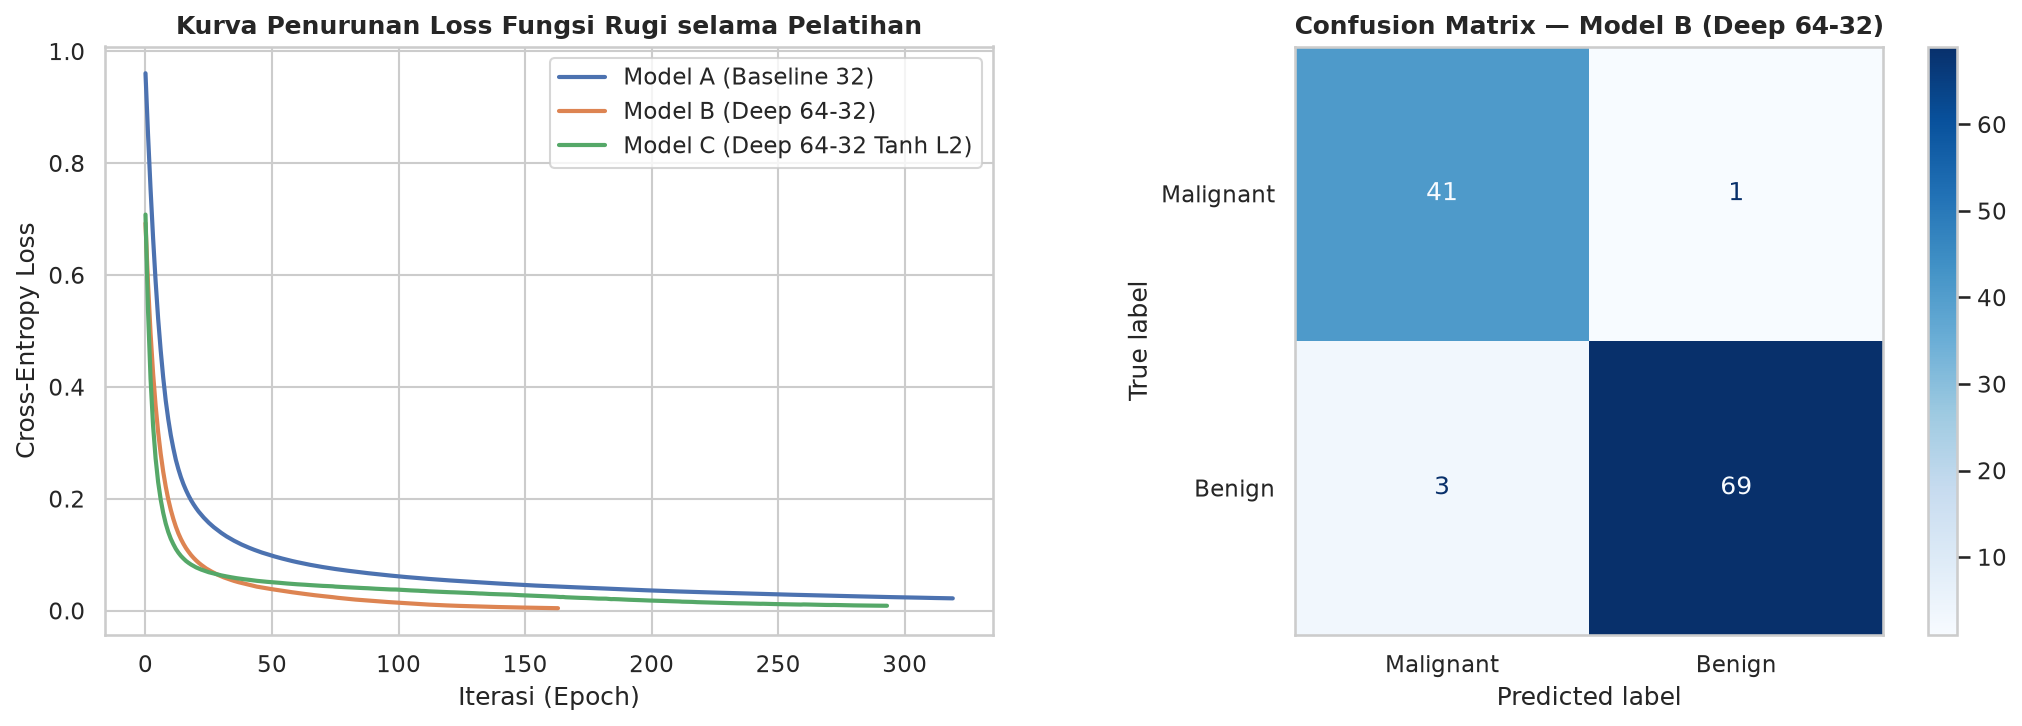

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, curve in loss_curves_clf.items():
    axes[0].plot(curve, label=name, lw=2)
axes[0].set_title("Kurva Penurunan Loss Fungsi Rugi selama Pelatihan", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Iterasi (Epoch)")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

best_clf = configs_clf['Model B (Deep 64-32)']
cm_best = confusion_matrix(y_can_te, best_clf.predict(X_can_te_sc))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=['Malignant', 'Benign'])
disp.plot(cmap='Blues', ax=axes[1], values_format='d')
axes[1].set_title("Confusion Matrix — Model B (Deep 64-32)", fontsize=12, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

### 4.3 Tugas 2 (Regresi Mandiri): California Housing
Untuk studi kasus regresi mandiri, digunakan dataset standar industri **California Housing**. Dataset ini merangkum data sensus tahun 1990 di California dengan 20.640 blok sensus dan 8 fitur demografis/geografis (`MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, `Longitude`) untuk memprediksi harga median rumah (`MedHouseVal`, dalam satuan ratusan ribu dolar AS).


In [30]:
california = fetch_california_housing(as_frame=True)
df_cal = california.frame

print(f"Dimensi dataset California Housing: {df_cal.shape}")
print("Lima baris data pertama:")
df_cal.head()

Dimensi dataset California Housing: (20640, 9)
Lima baris data pertama:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


#### Penskalaan dan Pemisahan Data Latih-Uji Regresi


In [31]:
X_cal = california.data
y_cal = california.target

X_cal_tr, X_cal_te, y_cal_tr, y_cal_te = train_test_split(
    X_cal, y_cal, test_size=0.2, random_state=42
)

scaler_cal = StandardScaler().fit(X_cal_tr)
X_cal_tr_sc = scaler_cal.transform(X_cal_tr)
X_cal_te_sc = scaler_cal.transform(X_cal_te)

print(f"Set pelatihan California: {X_cal_tr_sc.shape}")
print(f"Set pengujian California: {X_cal_te_sc.shape}")

Set pelatihan California: (16512, 8)
Set pengujian California: (4128, 8)


#### Eksperimen 3 Arsitektur Model MLPRegressor
1. **Model A (Baseline):** 1 lapisan tersembunyi `(64,)`, aktivasi ReLU, optimizer Adam, max_iter=500.
2. **Model B (Deep 2-Layer):** 2 lapisan tersembunyi `(128, 64)`, aktivasi ReLU, optimizer Adam, max_iter=500.
3. **Model C (Deep 3-Layer + Early Stopping):** 3 lapisan tersembunyi `(128, 64, 32)`, aktivasi ReLU, optimizer Adam, $\alpha=0.001$, `early_stopping=True`.


In [32]:
configs_reg = {
    'Model A (Baseline 64)': MLPRegressor(hidden_layer_sizes=(64,), max_iter=500, random_state=42),
    'Model B (Deep 128-64)': MLPRegressor(hidden_layer_sizes=(128, 64), max_iter=500, random_state=42),
    'Model C (Deep 128-64-32 Stop)': MLPRegressor(hidden_layer_sizes=(128, 64, 32), alpha=0.001, early_stopping=True, max_iter=500, random_state=42)
}

hasil_reg = []
preds_reg = {}

for name, reg_model in configs_reg.items():
    reg_model.fit(X_cal_tr_sc, y_cal_tr)
    y_pred_m = reg_model.predict(X_cal_te_sc)
    preds_reg[name] = y_pred_m

    mae_m = mean_absolute_error(y_cal_te, y_pred_m)
    mse_m = mean_squared_error(y_cal_te, y_pred_m)
    rmse_m = np.sqrt(mse_m)
    r2_m = r2_score(y_cal_te, y_pred_m)

    hasil_reg.append({
        'Model': name,
        'MAE': mae_m,
        'MSE': mse_m,
        'RMSE': rmse_m,
        'R2 Score': r2_m,
        'Iterasi': reg_model.n_iter_,
        'Loss Akhir': reg_model.loss_
    })

df_hasil_reg = pd.DataFrame(hasil_reg)
print("=== Tabel Perbandingan Performa Model Regresi MLP ===")
df_hasil_reg

=== Tabel Perbandingan Performa Model Regresi MLP ===


,Model,MAE,MSE,RMSE,R2 Score,Iterasi,Loss Akhir
0,Model A (Baseline 64),0.372559,0.294636,0.542804,0.775157,220,0.140245
1,Model B (Deep 128-64),0.344786,0.260102,0.510002,0.801511,123,0.111833
2,Model C (Deep 128-64-32 Stop),0.346145,0.262855,0.512694,0.799410,83,0.105875


#### Visualisasi Evaluasi Model Regresi Terbaik: Scatter Plot Aktual vs Prediksi
Menampilkan grafik sebaran (*scatter plot*) antara harga rumah aktual dengan prediksi model regresi terbaik dilengkapi garis ideal identitas $y=x$.


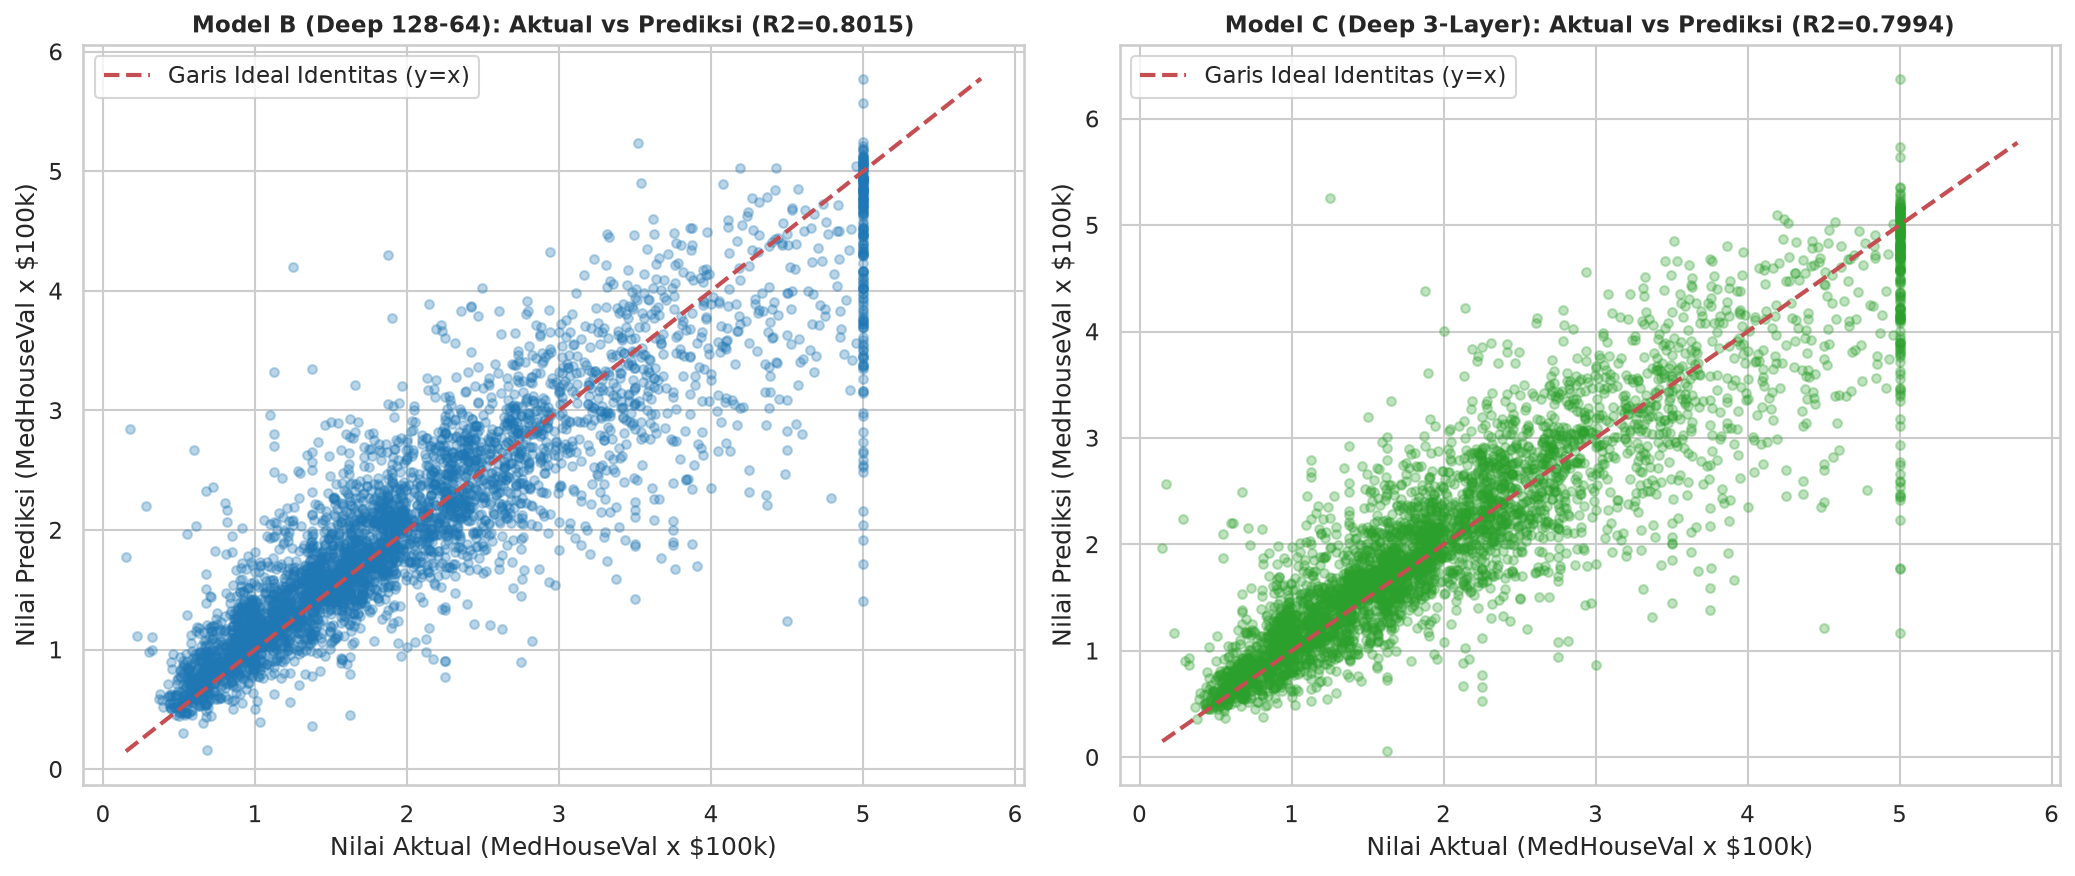

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_cal_te, preds_reg['Model B (Deep 128-64)'], alpha=0.3, color='#1f77b4', s=18)
min_val = min(y_cal_te.min(), preds_reg['Model B (Deep 128-64)'].min())
max_val = max(y_cal_te.max(), preds_reg['Model B (Deep 128-64)'].max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Garis Ideal Identitas (y=x)')
axes[0].set_title(f"Model B (Deep 128-64): Aktual vs Prediksi (R2={df_hasil_reg.loc[1, 'R2 Score']:.4f})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Nilai Aktual (MedHouseVal x $100k)")
axes[0].set_ylabel("Nilai Prediksi (MedHouseVal x $100k)")
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(y_cal_te, preds_reg['Model C (Deep 128-64-32 Stop)'], alpha=0.3, color='#2ca02c', s=18)
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Garis Ideal Identitas (y=x)')
axes[1].set_title(f"Model C (Deep 3-Layer): Aktual vs Prediksi (R2={df_hasil_reg.loc[2, 'R2 Score']:.4f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Nilai Aktual (MedHouseVal x $100k)")
axes[1].set_ylabel("Nilai Prediksi (MedHouseVal x $100k)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Kesimpulan Praktikum Pertemuan 8
1. **Multilayer Perceptron (MLP)** mampu memodelkan persoalan klasifikasi dan regresi secara efektif melalui pembelajaran terawasi berulang (*Backpropagation*) dengan fungsi aktivasi non-linier.
2. Penskalaan fitur numerik menggunakan **`StandardScaler`** merupakan tahapan mutlak sebelum melatih model jaringan syaraf tiruan. Tanpa penskalaan, optimasi gradien rentan macet pada permukaan rugi datar (*vanishing/exploding gradient*) atau gagal konvergen seperti yang diamati pada `MLPRegressor` tanpa penskalaan.
3. Struktur arsitektur (jumlah *hidden layers*, jumlah neuron per lapisan, serta penambahan regularisasi $L_2$ dan *early stopping*) terbukti mampu menyeimbangkan kapasitas model untuk menangkap pola kompleks tanpa terjebak dalam *overfitting*.
